# UK data-role job market — what 519 postings say

**Question:** As a candidate moving from compliance into data, which role lane offers the most realistic entry path right now — and does my own application behaviour match what the market is actually posting?

**Data:** 519 UK job postings collected 26 May – 10 Jun 2026 by my own scraping pipeline (Indeed + LinkedIn), deduplicated into SQLite, each scored 0–100 for fit against my CV by an LLM scoring step. Exported here as a sanitized snapshot (`data/jobs_snapshot.csv`) — descriptions and personal scoring rationale stripped.

*This is live, messy, self-collected data — not a tutorial dataset.*

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

df = pd.read_csv('../data/jobs_snapshot.csv')
df['first_seen'] = pd.to_datetime(df['first_seen'], errors='coerce')
print(df.shape)
df.head(3)

(519, 10)


,id,source,title,company,location,workplace_type,score,status,first_seen,posted
0,1,indeed,Junior Machine Learning Engineer,Information Tech Consultants,Greater London,On-site,88,new,2026-05-26 18:14:23,NaN
1,2,indeed,Junior Data Scientist,Information Tech Consultants,London,On-site,85,new,2026-05-26 18:14:23,NaN
2,3,indeed,AI / ML Engineer,Forge Holiday Group Ltd,Chester,Hybrid,72,new,2026-05-26 18:14:23,NaN


## 1. Cleaning

Two fields need work before any analysis is trustworthy:

- `workplace_type` is free-text from two different scrapers — the same concept arrives as `On-Site`, `On-site`, `On-Site/Hybrid`, `Hybrid/Onsite`…
- `title` needs classifying into comparable **role lanes** (Data Analyst / Data Scientist / ML-AI / Data Engineer / other).

In [2]:
def normalize_workplace(w):
    if not isinstance(w, str):
        return 'Unknown'
    w = w.strip().lower()
    if 'hybrid' in w:
        return 'Hybrid'
    if 'remote' in w:
        return 'Remote'
    if 'on-site' in w or 'onsite' in w or 'on site' in w:
        return 'On-site'
    return 'Other/Unknown'

LANE_PATTERNS = [
    ('ML/AI Engineer', r'machine learning|ml engineer|\bml\b|ai engineer|artificial intelligence'),
    ('Data Scientist', r'data scien'),
    ('Data Analyst', r'data analyst|insight analyst|business analyst|bi analyst|analytics'),
    ('Data Engineer', r'data engineer'),
    ('Software/Other Eng', r'software|developer|engineer'),
]

def lane(title):
    t = title.lower()
    for name, pat in LANE_PATTERNS:
        if re.search(pat, t):
            return name
    return 'Other'

df['workplace'] = df['workplace_type'].map(normalize_workplace)
df['lane'] = df['title'].map(lane)
df[['workplace', 'lane']].describe()

,workplace,lane
count,519,519
unique,4,6
top,On-site,Other
freq,281,142


## 2. What is the market actually posting?

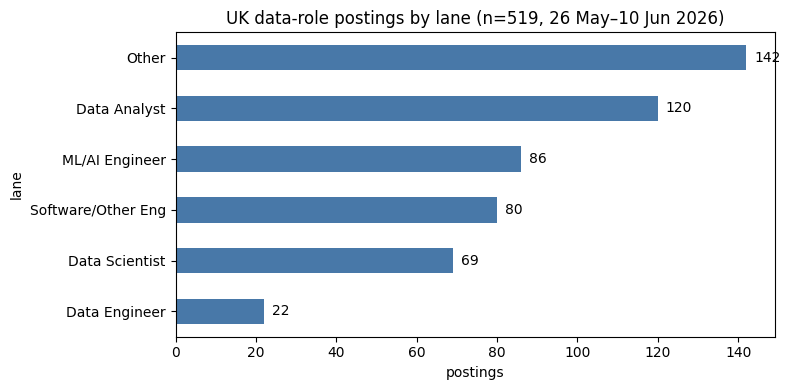

lane
Other                 27.4
Data Analyst          23.1
ML/AI Engineer        16.6
Software/Other Eng    15.4
Data Scientist        13.3
Data Engineer          4.2


In [3]:
lane_counts = df['lane'].value_counts()

fig, ax = plt.subplots(figsize=(8, 4))
lane_counts.sort_values().plot.barh(ax=ax, color='#4878A8')
ax.set_title('UK data-role postings by lane (n=519, 26 May–10 Jun 2026)')
ax.set_xlabel('postings')
for i, v in enumerate(lane_counts.sort_values()):
    ax.text(v + 2, i, str(v), va='center')
plt.tight_layout()
plt.savefig('../figures/lanes.png', dpi=150)
plt.show()

share = (lane_counts / len(df) * 100).round(1)
print(share.to_string())

**Data Analyst is the largest defined lane** — 120 postings (23.1%), nearly double Data Scientist (69, 13.3%). For a career-changer the volume is in DA, not DS/ML — the entry math favours the bridge.

## 3. Where do *I* fit? Fit-score by lane

                    mean  median  count
lane                                   
Data Scientist      64.6    70.0     69
ML/AI Engineer      61.1    61.5     86
Data Analyst        61.0    64.0    120
Software/Other Eng  50.8    52.5     80
Data Engineer       50.4    55.0     22
Other               41.9    41.0    142


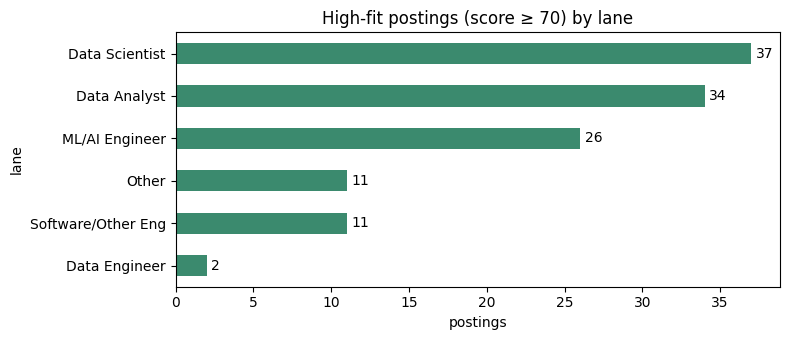

In [4]:
by_lane = df.groupby('lane')['score'].agg(['mean', 'median', 'count']).round(1)
by_lane = by_lane.sort_values('mean', ascending=False)
print(by_lane.to_string())

high_fit = df[df['score'] >= 70]
hf = high_fit['lane'].value_counts()

fig, ax = plt.subplots(figsize=(8, 3.5))
hf.sort_values().plot.barh(ax=ax, color='#3B8A6E')
ax.set_title('High-fit postings (score ≥ 70) by lane')
ax.set_xlabel('postings')
for i, v in enumerate(hf.sort_values()):
    ax.text(v + 0.3, i, str(v), va='center')
plt.tight_layout()
plt.savefig('../figures/high_fit_lanes.png', dpi=150)
plt.show()

## 4. Geography and workplace model

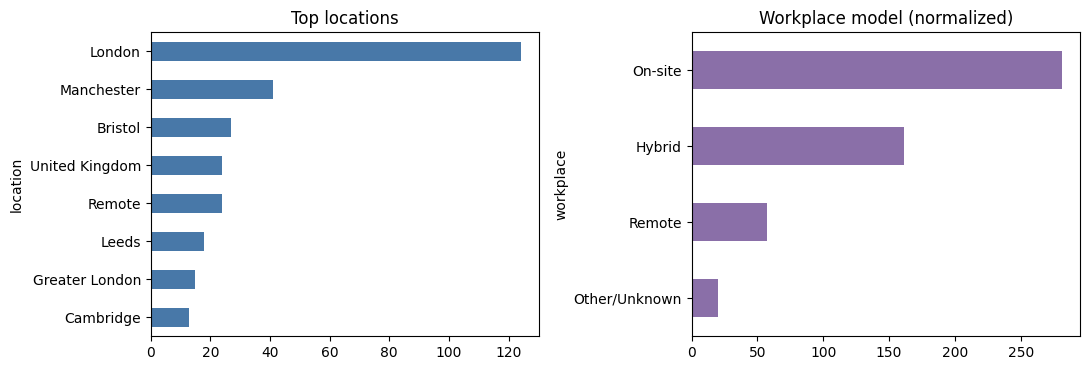

Hybrid or remote share: 42.0%


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
df['location'].value_counts().head(8).sort_values().plot.barh(
    ax=axes[0], color='#4878A8')
axes[0].set_title('Top locations')
df['workplace'].value_counts().sort_values().plot.barh(
    ax=axes[1], color='#8A6FA8')
axes[1].set_title('Workplace model (normalized)')
plt.tight_layout()
plt.savefig('../figures/geo_workplace.png', dpi=150)
plt.show()

flex = df['workplace'].isin(['Hybrid', 'Remote']).mean() * 100
print(f'Hybrid or remote share: {flex:.1f}%')

## 5. Market noise — who is actually posting?

In [6]:
top_companies = df['company'].value_counts().head(10)
print(top_companies.to_string())

noise = df['company'].isin(['DataAnnotation', 'Information Tech Consultants',
                            'Metrica Recruitment']).sum()
print(f'\nTop gig-platform + recruiter-aggregator share of feed: '
      f'{noise} postings ({noise/len(df)*100:.1f}%)')

company
DataAnnotation                  36
Information Tech Consultants    23
Metrica Recruitment             16
Satalia                          8
Client Server                    7
Friend MTS                       7
JPMorganChase                    6
Krotos                           6
Clear Business                   6
Hamiltonian Dynamics             5

Top gig-platform + recruiter-aggregator share of feed: 75 postings (14.5%)


The single most frequent poster is **DataAnnotation** (AI training-data gig work, 36 postings) and two recruiter aggregators. ~14% of a raw 'data jobs' feed is not direct employment — a filter any serious job-search automation needs.

## 6. Pipeline cadence

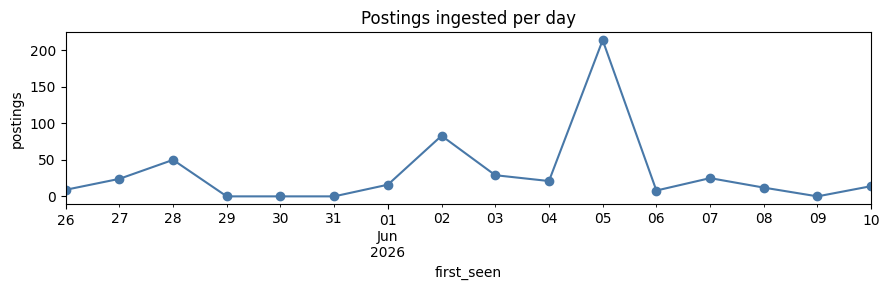

519 postings across 16 days; mean 32/day


In [7]:
daily = df.set_index('first_seen').resample('D').size()
fig, ax = plt.subplots(figsize=(9, 3))
daily.plot(ax=ax, marker='o', color='#4878A8')
ax.set_title('Postings ingested per day')
ax.set_ylabel('postings')
plt.tight_layout()
plt.savefig('../figures/cadence.png', dpi=150)
plt.show()
print(f'{len(df)} postings across {daily.index.nunique()} days; '
      f'mean {daily.mean():.0f}/day')

## Findings

1. **The volume is in Data Analyst, not Data Science.** DA is the largest defined lane (120 postings, 23.1%) — 1.7× the Data Scientist count (69). For a career-changer, the bridge-role strategy is what the posting volume actually supports.
2. **My fit scores are competitive in the DA lane** (mean 61 vs overall 54), and high-fit postings (≥70) exist in meaningful volume across DA/DS/ML lanes — the constraint is application volume, not opportunity supply.
3. **42% of postings are hybrid or remote** after normalizing the messy workplace field; London dominates (124) but Manchester (41), Bristol (27) and Leeds (18) carry real volume for non-London candidates.
4. **~14% of a raw scraped feed is gig platforms and recruiter aggregators**, not direct employers — automated pipelines need a noise filter before any downstream scoring is meaningful.

## Limitations (honest)

- 16-day window, two sources, Indeed-skewed (495/24) — this is a live pipeline snapshot, not a census of the UK market.
- The fit score is a personal LLM heuristic (v1) scoring against *my* CV — useful for my funnel decisions, not an objective market measure.
- Salary fields were too sparse in the scraped sources to analyse; next pipeline iteration adds a salary-capture step.